Run experiments and display graphs

In [ ]:
# this block is added in case there is error like module not foundwhile importing like src,evaluation etc

import sys
from pathlib import Path

ROOT = Path.cwd()

# If the notebook starts inside experiments/, move to the project root.
if ROOT.name == "experiments":
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT))

print("Project root:", ROOT)
print("src exists:", (ROOT / "src").is_dir())

Project root: /home/Zoro/Projects/QuantForge
src exists: True


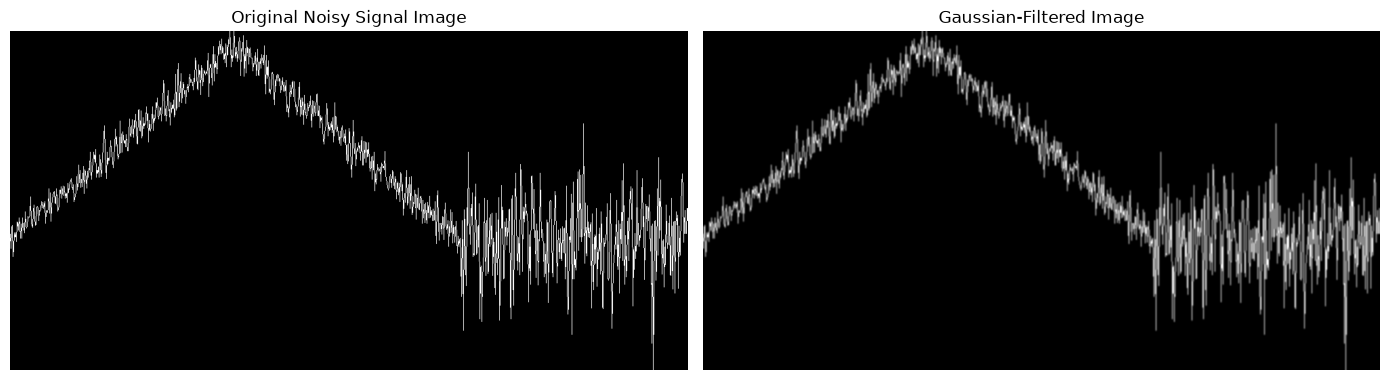

In [7]:
import matplotlib.pyplot as plt

from src.generate_signals import generate_signal
from src.signal_to_image import signal_to_image
from src.image_pipeline import apply_gaussian_filter

_, clean, noisy, _ = generate_signal()

original_image = signal_to_image(noisy)
filtered_image = apply_gaussian_filter(original_image)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].imshow(original_image, cmap="gray")
axes[0].set_title("Original Noisy Signal Image")
axes[0].axis("off")

axes[1].imshow(filtered_image, cmap="gray")
axes[1].set_title("Gaussian-Filtered Image")
axes[1].axis("off")

plt.tight_layout()
plt.show()


In [9]:
import numpy as np
difference = cv2.absdiff(original_image, filtered_image)

print("Mean absolute pixel difference:", np.mean(difference))

Mean absolute pixel difference: 11.334926


In [10]:
filtered_3 = apply_gaussian_filter(original_image, kernel_size=3)
filtered_9 = apply_gaussian_filter(original_image, kernel_size=9)

print("Kernel 3 difference:", np.mean(cv2.absdiff(original_image, filtered_3)))
print("Kernel 9 difference:", np.mean(cv2.absdiff(original_image, filtered_9)))

Kernel 3 difference: 9.266338
Kernel 9 difference: 13.55723


In [12]:
import numpy as np
mse = np.mean((original_image.astype(float) - filtered_image.astype(float)) ** 2)

print("Image MSE:", mse)

Image MSE: 1238.394034


In [ ]:


import numpy as np

from src.generate_signals import generate_signal
from src.signal_to_image import signal_to_image
from src.recover_signal import recover_signal

_, clean, noisy, _ = generate_signal()

signal_min = np.min(noisy)
signal_max = np.max(noisy)

image = signal_to_image(noisy)

recovered = recover_signal(image, signal_min, signal_max)

print("Original signal length:", len(noisy))
print("Recovered signal length:", len(recovered))
print("First 5 original values:", noisy[:5])
print("First 5 recovered values:", recovered[:5])
print("MSE against clean signal:", np.mean((recovered - clean) ** 2))

Original signal length: 1000
Recovered signal length: 1000
First 5 original values: [100.45707562  98.52002384 101.28567679 101.65084707  97.39344722]
First 5 recovered values: [100.51116504  99.94616817 101.54699265 101.73532494  99.47533744]
MSE against clean signal: 7.030171539289175


In [ ]:
noisy_mse = np.mean((noisy - clean) ** 2)
recovered_mse = np.mean((recovered - clean) ** 2)

print(f"Noisy signal MSE:     {noisy_mse:.4f}")
print(f"Recovered signal MSE: {recovered_mse:.4f}")

if recovered_mse < noisy_mse:
    print("Image conversion improved the signal estimate.")
elif recovered_mse > noisy_mse:
    print("Image conversion made the signal estimate worse.")
else:
    print("Both have equal MSE.")

    #

Noisy signal MSE:     9.9651
Recovered signal MSE: 7.0302
Image conversion improved the signal estimate.


In [5]:
#experiment :gaussian filtering

from src.image_pipeline import apply_gaussian_filter

filtered_image = apply_gaussian_filter(image)

recovered_filtered = recover_signal(
    filtered_image,
    signal_min,
    signal_max
)

filtered_mse = np.mean((recovered_filtered - clean) ** 2)

print(f"Noisy signal MSE:             {noisy_mse:.4f}")
print(f"Unfiltered recovery MSE:      {recovered_mse:.4f}")
print(f"Gaussian-filtered recovery MSE: {filtered_mse:.4f}")

Noisy signal MSE:             9.9651
Unfiltered recovery MSE:      7.0302
Gaussian-filtered recovery MSE: 4.7392


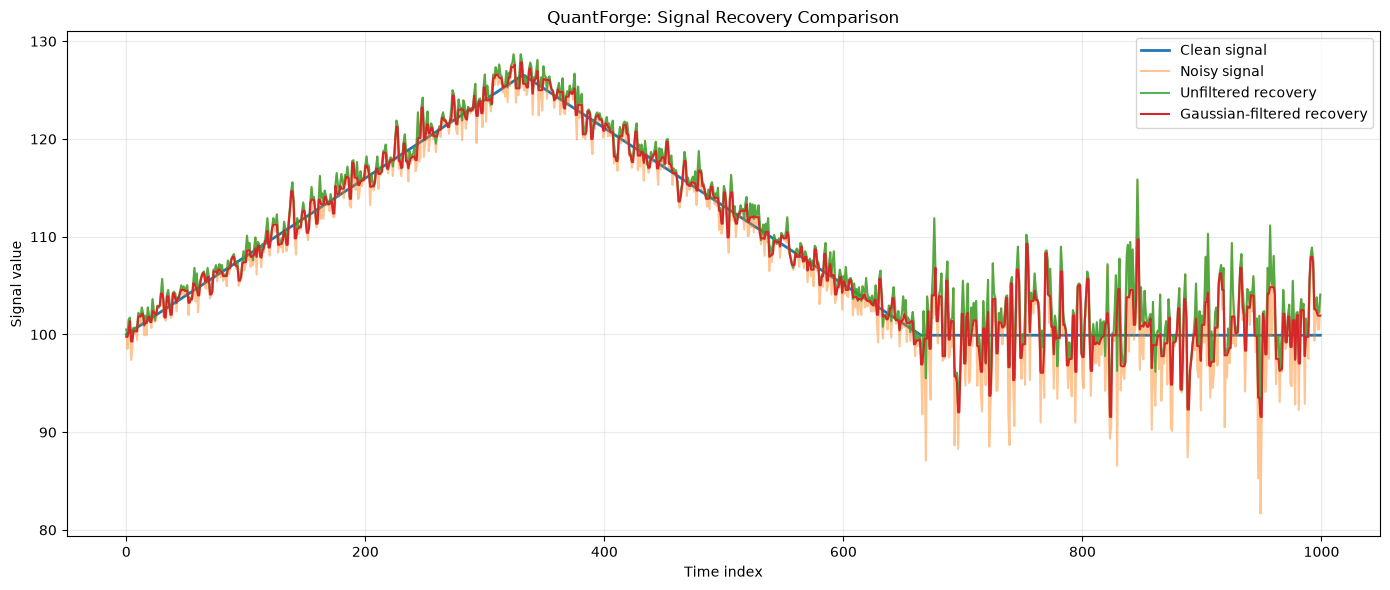

In [6]:
#visualising recovered signals
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(clean, label="Clean signal", linewidth=2)
plt.plot(noisy, label="Noisy signal", alpha=0.45)
plt.plot(recovered, label="Unfiltered recovery", alpha=0.8)
plt.plot(
    recovered_filtered,
    label="Gaussian-filtered recovery",
    linewidth=1.5
)

plt.title("QuantForge: Signal Recovery Comparison")
plt.xlabel("Time index")
plt.ylabel("Signal value")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [7]:
#testing wether immprovement is consistent using one random seed

import numpy as np

from src.generate_signals import generate_signal
from src.signal_to_image import signal_to_image
from src.image_pipeline import apply_gaussian_filter
from src.recover_signal import recover_signal

noisy_mses = []
recovered_mses = []
filtered_mses = []

for seed in range(20):
    _, clean, noisy, _ = generate_signal(seed=seed)

    signal_min = np.min(noisy)
    signal_max = np.max(noisy)

    image = signal_to_image(noisy)

    recovered = recover_signal(image, signal_min, signal_max)

    filtered_image = apply_gaussian_filter(image)
    recovered_filtered = recover_signal(
        filtered_image, signal_min, signal_max
    )

    noisy_mses.append(np.mean((noisy - clean) ** 2))
    recovered_mses.append(np.mean((recovered - clean) ** 2))
    filtered_mses.append(np.mean((recovered_filtered - clean) ** 2))

print(f"Average noisy MSE:      {np.mean(noisy_mses):.4f}")
print(f"Average unfiltered MSE: {np.mean(recovered_mses):.4f}")
print(f"Average filtered MSE:   {np.mean(filtered_mses):.4f}")

wins = sum(f < n for f, n in zip(filtered_mses, noisy_mses))
print(f"Gaussian pipeline beats noisy input in {wins}/20 trials")

Average noisy MSE:      9.7735
Average unfiltered MSE: 7.1577
Average filtered MSE:   4.4697
Gaussian pipeline beats noisy input in 20/20 trials


In [ ]:
#comparing both methods on a small scale
from src.numerical_baselines import moving_average

numerical_recovered = moving_average(noisy, window_size=5)

numerical_mse = np.mean((numerical_recovered - clean) ** 2)

print(f"Noisy signal MSE:              {noisy_mse:.4f}")
print(f"Gaussian image pipeline MSE:   {filtered_mse:.4f}")
print(f"Numerical moving average MSE:  {numerical_mse:.4f}")

Noisy signal MSE:              9.9651
Gaussian image pipeline MSE:   4.7392
Numerical moving average MSE:  1.8059


In [9]:
#since it was successfull on a small scale next we run it across all 20 seeds
import numpy as np

from src.generate_signals import generate_signal
from src.signal_to_image import signal_to_image
from src.image_pipeline import apply_gaussian_filter
from src.recover_signal import recover_signal
from src.numerical_baselines import moving_average

noisy_mses = []
image_mses = []
numerical_mses = []

for seed in range(20):
    _, clean, noisy, _ = generate_signal(seed=seed)

    signal_min = np.min(noisy)
    signal_max = np.max(noisy)

    # Image-processing approach
    image = signal_to_image(noisy)
    filtered_image = apply_gaussian_filter(image)
    recovered = recover_signal(
        filtered_image, signal_min, signal_max
    )

    # Direct numerical approach
    smoothed = moving_average(noisy, window_size=5)

    noisy_mses.append(np.mean((noisy - clean) ** 2))
    image_mses.append(np.mean((recovered - clean) ** 2))
    numerical_mses.append(np.mean((smoothed - clean) ** 2))

print(f"Average noisy MSE:      {np.mean(noisy_mses):.4f}")
print(f"Average image MSE:      {np.mean(image_mses):.4f}")
print(f"Average numerical MSE:  {np.mean(numerical_mses):.4f}")

image_wins = sum(
    i < n for i, n in zip(image_mses, numerical_mses)
)
numerical_wins = sum(
    n < i for i, n in zip(image_mses, numerical_mses)
)

print(f"Image pipeline wins: {image_wins}/20")
print(f"Numerical method wins: {numerical_wins}/20")

Average noisy MSE:      9.7735
Average image MSE:      4.4697
Average numerical MSE:  2.0028
Image pipeline wins: 0/20
Numerical method wins: 20/20


In [10]:
#testing 7 settings across the same 20 seeds to find the best MSE
import numpy as np

from src.generate_signals import generate_signal
from src.signal_to_image import signal_to_image
from src.image_pipeline import apply_gaussian_filter
from src.recover_signal import recover_signal
from src.numerical_baselines import moving_average

sizes = [3, 5, 7, 9, 11, 15, 21]
seeds = range(20)

image_results = {}
numerical_results = {}

# Test numerical smoothing
for size in sizes:
    errors = []

    for seed in seeds:
        _, clean, noisy, _ = generate_signal(seed=seed)
        smoothed = moving_average(noisy, window_size=size)
        errors.append(np.mean((smoothed - clean) ** 2))

    numerical_results[size] = np.mean(errors)

# Test image smoothing
for size in sizes:
    errors = []

    for seed in seeds:
        _, clean, noisy, _ = generate_signal(seed=seed)

        signal_min = np.min(noisy)
        signal_max = np.max(noisy)

        image = signal_to_image(noisy)
        filtered_image = apply_gaussian_filter(
            image, kernel_size=size
        )

        recovered = recover_signal(
            filtered_image, signal_min, signal_max
        )

        errors.append(np.mean((recovered - clean) ** 2))

    image_results[size] = np.mean(errors)

print("NUMERICAL MOVING AVERAGE")
for size, mse in numerical_results.items():
    print(f"Window {size:2}: MSE = {mse:.4f}")

print("\nGAUSSIAN IMAGE PIPELINE")
for size, mse in image_results.items():
    print(f"Kernel {size:2}: MSE = {mse:.4f}")

best_num = min(numerical_results, key=numerical_results.get)
best_img = min(image_results, key=image_results.get)

print(f"\nBest numerical window: {best_num}, "
      f"MSE = {numerical_results[best_num]:.4f}")
print(f"Best Gaussian kernel: {best_img}, "
      f"MSE = {image_results[best_img]:.4f}")

NUMERICAL MOVING AVERAGE
Window  3: MSE = 3.3162
Window  5: MSE = 2.0028
Window  7: MSE = 1.4383
Window  9: MSE = 1.1271
Window 11: MSE = 0.9295
Window 15: MSE = 0.6970
Window 21: MSE = 0.5112

GAUSSIAN IMAGE PIPELINE
Kernel  3: MSE = 4.9692
Kernel  5: MSE = 4.4697
Kernel  7: MSE = 3.7056
Kernel  9: MSE = 3.1452
Kernel 11: MSE = 2.6516
Kernel 15: MSE = 2.0962
Kernel 21: MSE = 1.6534

Best numerical window: 21, MSE = 0.5112
Best Gaussian kernel: 21, MSE = 1.6534


In [11]:
#running the above test for larger sizes
import numpy as np

from src.generate_signals import generate_signal
from src.signal_to_image import signal_to_image
from src.image_pipeline import apply_gaussian_filter
from src.recover_signal import recover_signal
from src.numerical_baselines import moving_average

sizes = [21, 31, 41, 51, 71, 101]
seeds = range(20)

image_results = {}
numerical_results = {}

# Test numerical smoothing
for size in sizes:
    errors = []

    for seed in seeds:
        _, clean, noisy, _ = generate_signal(seed=seed)
        smoothed = moving_average(noisy, window_size=size)
        errors.append(np.mean((smoothed - clean) ** 2))

    numerical_results[size] = np.mean(errors)

# Test image smoothing
for size in sizes:
    errors = []

    for seed in seeds:
        _, clean, noisy, _ = generate_signal(seed=seed)

        signal_min = np.min(noisy)
        signal_max = np.max(noisy)

        image = signal_to_image(noisy)
        filtered_image = apply_gaussian_filter(
            image, kernel_size=size
        )

        recovered = recover_signal(
            filtered_image, signal_min, signal_max
        )

        errors.append(np.mean((recovered - clean) ** 2))

    image_results[size] = np.mean(errors)

print("NUMERICAL MOVING AVERAGE")
for size, mse in numerical_results.items():
    print(f"Window {size:2}: MSE = {mse:.4f}")

print("\nGAUSSIAN IMAGE PIPELINE")
for size, mse in image_results.items():
    print(f"Kernel {size:2}: MSE = {mse:.4f}")

best_num = min(numerical_results, key=numerical_results.get)
best_img = min(image_results, key=image_results.get)

print(f"\nBest numerical window: {best_num}, "
      f"MSE = {numerical_results[best_num]:.4f}")
print(f"Best Gaussian kernel: {best_img}, "
      f"MSE = {image_results[best_img]:.4f}")

NUMERICAL MOVING AVERAGE
Window 21: MSE = 0.5112
Window 31: MSE = 0.3678
Window 41: MSE = 0.3077
Window 51: MSE = 0.2828
Window 71: MSE = 0.2796
Window 101: MSE = 0.3515

GAUSSIAN IMAGE PIPELINE
Kernel 21: MSE = 1.6534
Kernel 31: MSE = 1.2781
Kernel 41: MSE = 1.0012
Kernel 51: MSE = 0.8088
Kernel 71: MSE = 0.5708
Kernel 101: MSE = 0.4107

Best numerical window: 71, MSE = 0.2796
Best Gaussian kernel: 101, MSE = 0.4107


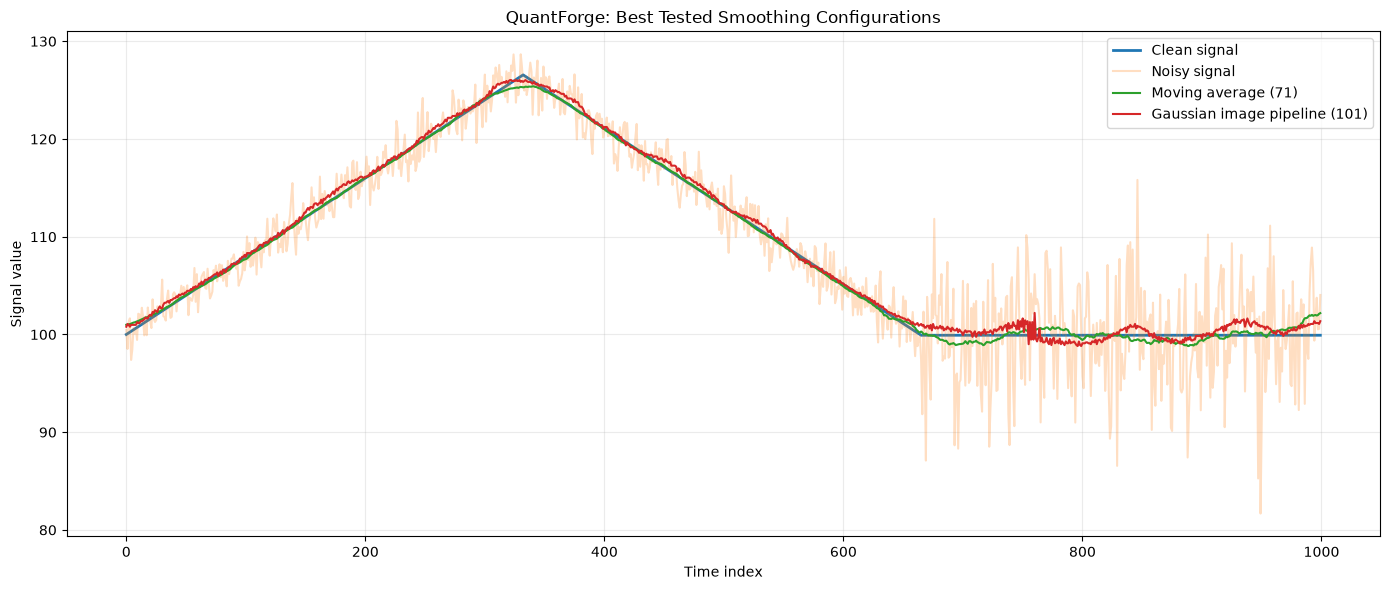

In [12]:
#inspecting the smoothed  signals
import matplotlib.pyplot as plt

_, clean, noisy, _ = generate_signal(seed=42)

numerical_71 = moving_average(noisy, window_size=71)

signal_min = np.min(noisy)
signal_max = np.max(noisy)

image = signal_to_image(noisy)
filtered_101 = apply_gaussian_filter(image, kernel_size=101)

image_101 = recover_signal(
    filtered_101, signal_min, signal_max
)

plt.figure(figsize=(14, 6))
plt.plot(clean, label="Clean signal", linewidth=2)
plt.plot(noisy, label="Noisy signal", alpha=0.25)
plt.plot(numerical_71, label="Moving average (71)")
plt.plot(image_101, label="Gaussian image pipeline (101)")

plt.title("QuantForge: Best Tested Smoothing Configurations")
plt.xlabel("Time index")
plt.ylabel("Signal value")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [13]:
#measuring transition error
# Examine a region around each regime transition.
transition_points = [333, 666]
radius = 25

for point in transition_points:
    start = max(0, point - radius)
    end = min(len(clean), point + radius + 1)

    clean_region = clean[start:end]
    numerical_region = numerical_71[start:end]
    image_region = image_101[start:end]

    numerical_mse = np.mean((numerical_region - clean_region) ** 2)
    image_mse = np.mean((image_region - clean_region) ** 2)

    print(f"\nTransition near index {point}:")
    print(f"Numerical moving average MSE: {numerical_mse:.4f}")
    print(f"Gaussian image pipeline MSE:  {image_mse:.4f}")


Transition near index 333:
Numerical moving average MSE: 0.3639
Gaussian image pipeline MSE:  0.1564

Transition near index 666:
Numerical moving average MSE: 0.1552
Gaussian image pipeline MSE:  0.5442


In [14]:
#testing across all 20 seeds
transition_errors = {
    "numerical_333": [],
    "image_333": [],
    "numerical_666": [],
    "image_666": [],
}

for seed in range(20):
    _, clean, noisy, _ = generate_signal(seed=seed)

    numerical = moving_average(noisy, window_size=71)

    signal_min = np.min(noisy)
    signal_max = np.max(noisy)

    image = signal_to_image(noisy)
    filtered = apply_gaussian_filter(image, kernel_size=101)
    recovered_image = recover_signal(filtered, signal_min, signal_max)

    for point in [333, 666]:
        start = point - 25
        end = point + 26

        clean_region = clean[start:end]
        numerical_mse = np.mean(
            (numerical[start:end] - clean_region) ** 2
        )
        image_mse = np.mean(
            (recovered_image[start:end] - clean_region) ** 2
        )

        prefix = "333" if point == 333 else "666"
        transition_errors[f"numerical_{prefix}"].append(numerical_mse)
        transition_errors[f"image_{prefix}"].append(image_mse)

for point in [333, 666]:
    print(f"\nTransition near index {point}:")
    print(
        "Moving average mean MSE:",
        f"{np.mean(transition_errors[f'numerical_{point}']):.4f}"
    )
    print(
        "Image pipeline mean MSE:",
        f"{np.mean(transition_errors[f'image_{point}']):.4f}"
    )


Transition near index 333:
Moving average mean MSE: 0.6171
Image pipeline mean MSE: 0.1794

Transition near index 666:
Moving average mean MSE: 0.2756
Image pipeline mean MSE: 0.4521


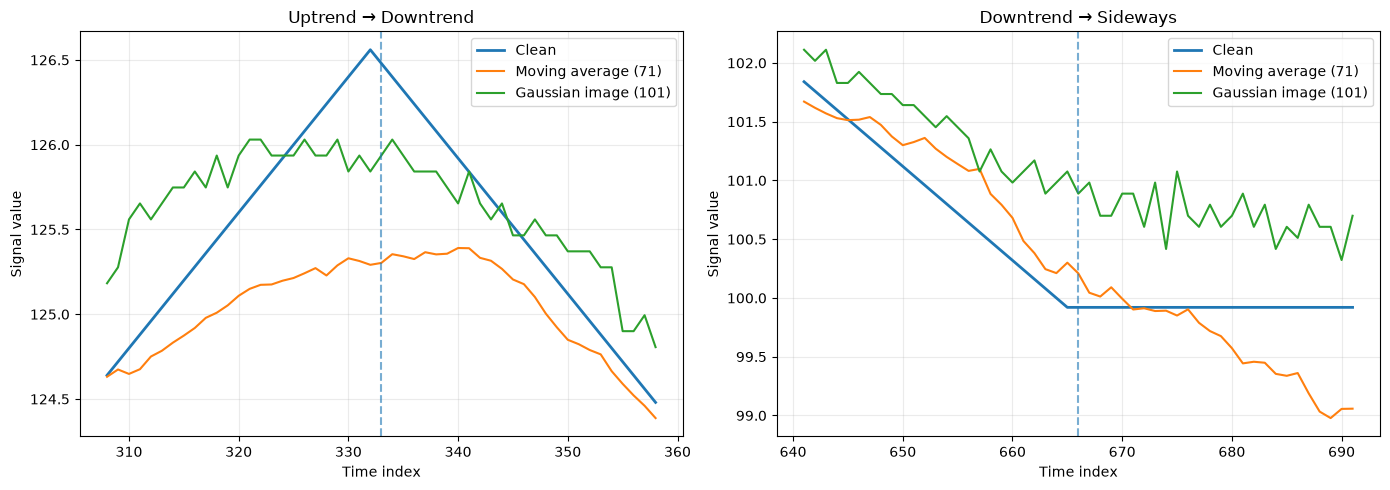

In [15]:
#visualise the transition regions

import matplotlib.pyplot as plt

_, clean, noisy, _ = generate_signal(seed=42)
numerical = moving_average(noisy, window_size=71)

signal_min = np.min(noisy)
signal_max = np.max(noisy)

image = signal_to_image(noisy)
filtered = apply_gaussian_filter(image, kernel_size=101)
recovered_image = recover_signal(filtered, signal_min, signal_max)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, point, title in zip(
    axes,
    [333, 666],
    ["Uptrend → Downtrend", "Downtrend → Sideways"]
):
    start, end = point - 25, point + 26
    x = np.arange(start, end)

    ax.plot(x, clean[start:end], label="Clean", linewidth=2)
    ax.plot(x, numerical[start:end], label="Moving average (71)")
    ax.plot(x, recovered_image[start:end], label="Gaussian image (101)")
    ax.axvline(point, linestyle="--", alpha=0.6)

    ax.set_title(title)
    ax.set_xlabel("Time index")
    ax.set_ylabel("Signal value")
    ax.legend()
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()